## Section 1.2 - Data Reduction

### Before starting
We load the merged dataset produced at the end of Module 1.1.


In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

DATASET123 = pd.read_csv("DATASET123.csv")
DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,creatinine,globulin,psa,coag_factor,diabetes,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention
0,1,1,1,2017-03-16,0,NaN,1935-01-01,82.203970,NaN,46.14,...,0.30,6.44,173.00,9.66,1,0,0,0,1,0
1,2,2,0,2005-03-31,0,NaN,1942-01-01,63.244353,NaN,50.14,...,0.15,1.84,0.10,7.65,0,0,0,0,0,0
2,3,2,0,2017-08-08,0,NaN,1959-01-01,58.600958,NaN,49.86,...,0.17,5.27,7.50,0.08,0,0,0,0,1,0
3,4,2,0,2008-01-02,0,NaN,1934-02-01,73.916496,NaN,49.57,...,0.24,5.03,0.35,7.26,0,0,0,0,0,0
4,5,2,0,2006-05-08,0,NaN,1949-03-01,57.185489,NaN,57.00,...,0.11,2.95,3.60,1.51,0,0,0,0,0,0


### Task 1 - Measures of test performance based on PSA

 We build a binary test result for each cutoff (PSA > 20 ng/mL and PSA > 100 ng/mL), then compute the confusion matrix components (TP, FP, FN, TN) against the true metastasis status.

In [35]:
DATASET123["test_result20"] = np.where(DATASET123["psa"] > 20, 1, 0)
DATASET123["test_result100"] = np.where(DATASET123["psa"] > 100, 1, 0)

def confusion_stats(df, col):
    TP = ((df["metastasis"] == 1) & (df[col] == 1)).sum()
    FP = ((df["metastasis"] == 0) & (df[col] == 1)).sum()
    FN = ((df["metastasis"] == 1) & (df[col] == 0)).sum()
    TN = ((df["metastasis"] == 0) & (df[col] == 0)).sum()
    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)
    accuracy = (TP + TN) / (TP + FP + FN + TN)
    return TP, FP, FN, TN, sensitivity, specificity, accuracy

TP20, FP20, FN20, TN20, sens20, spec20, acc20 = confusion_stats(DATASET123, "test_result20")
TP100, FP100, FN100, TN100, sens100, spec100, acc100 = confusion_stats(DATASET123, "test_result100")

perf_table = pd.DataFrame({
    "PSA > 20 ng/mL": [f"{sens20:.3f}", f"{spec20:.3f}", f"{acc20:.3f}"],
    "PSA > 100 ng/mL": [f"{sens100:.3f}", f"{spec100:.3f}", f"{acc100:.3f}"]
}, index=["Sensitivity", "Specificity", "Accuracy"])

perf_table

,PSA > 20 ng/mL,PSA > 100 ng/mL
Sensitivity,0.596,0.323
Specificity,0.672,0.867
Accuracy,0.645,0.670


Confusion matrix counts, for reference:

 | Cutoff | TP | FP | FN | TN |
 |---|---|---|---|---|
 | PSA > 20  | 251 | 242 | 170 | 496 |
 | PSA > 100 | 136 | 98  | 285 | 640 |


### Task 2 - Discussion

 - **Highest sensitivity**: PSA > 20 ng/mL (0.596 vs 0.323). Lower cutoff catches more true metastatic cases, at the cost of more false positives.
 - **Highest specificity**: PSA > 100 ng/mL (0.867 vs 0.672). Fewer false alarms, but misses roughly two-thirds of metastatic cases (sensitivity only 0.323).
 - **Recommended for screening**: PSA > 20 ng/mL. Screening needs high sensitivity to avoid missing cases that require follow-up; the cost of a false positive here is an additional (non-invasive) test, not a treatment decision.
 - **Recommended for confirming metastatic disease**: PSA > 100 ng/mL. Confirmation needs high specificity, since a positive result may lead to invasive procedures or treatment - this matches the historical use of PSA > 100 ng/mL as a proxy for metastatic disease (Thomsen et al., 2020).
 - **Trade-off**: neither cutoff is good on both axes simultaneously (accuracy is similar for both, ~0.64-0.67), which is the motivation for Task 3 - scanning all possible thresholds instead of picking two arbitrary ones.

### Task 3 - ROC curve and optimal cutoff

Instead of testing only two thresholds, we evaluate sensitivity vs. false positive rate across the full range of PSA values.


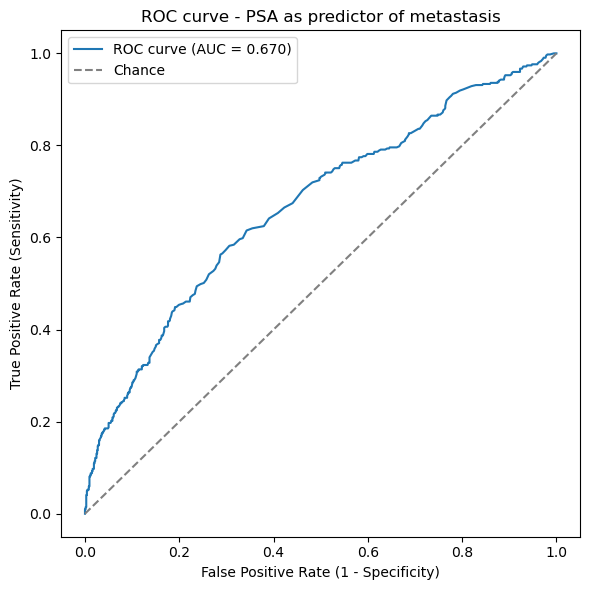

AUC = 0.670


In [36]:
fpr, tpr, thresholds = roc_curve(DATASET123["metastasis"], DATASET123["psa"])
auc = roc_auc_score(DATASET123["metastasis"], DATASET123["psa"])

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity)")
plt.title("ROC curve - PSA as predictor of metastasis")
plt.legend()
plt.tight_layout()
plt.show()

print(f"AUC = {auc:.3f}")


AUC = 0.670. Moderate discriminative ability - better than chance (0.5), but farfrom a strong single-marker test (which would be closer to 0.9+).


#### Youden Index

In [37]:
youden = tpr - fpr
best_index = np.argmax(youden)
optimal_cutoff_youden = thresholds[best_index]

print(f"Youden-optimal PSA cutoff: {optimal_cutoff_youden:.1f} ng/mL")
print(f"  Sensitivity: {tpr[best_index]:.3f}")
print(f"  Specificity: {1 - fpr[best_index]:.3f}")


Youden-optimal PSA cutoff: 23.0 ng/mL
  Sensitivity: 0.582
  Specificity: 0.694


#### Alternative method: maximum accuracy

 We scan the same thresholds and pick the one maximizing overall accuracy (weighted by class sizes, since accuracy is not just an average of sensitivity and specificity when classes are imbalanced).

In [38]:
n_pos = (DATASET123["metastasis"] == 1).sum()
n_neg = (DATASET123["metastasis"] == 0).sum()
accuracies = (tpr * n_pos + (1 - fpr) * n_neg) / (n_pos + n_neg)
best_acc_index = np.argmax(accuracies)
optimal_cutoff_acc = thresholds[best_acc_index]

print(f"Max-accuracy PSA cutoff: {optimal_cutoff_acc:.1f} ng/mL")
print(f"  Accuracy: {accuracies[best_acc_index]:.3f}")


Max-accuracy PSA cutoff: 134.0 ng/mL
  Accuracy: 0.679


The two methods disagree substantially: Youden Index selects a low cutoff (~23 ng/mL, close to the PSA > 20 ng/mL threshold already tested in Task 1), while maximum accuracy selects a much higher cutoff (~134 ng/mL, close to the PSA > 100 ng/mL threshold). This is expected: Youden Index treats sensitivity and specificity as equally important, while maximum accuracy is pulled toward whichever class is larger (here, non-metastatic patients dominate), which favors specificity over sensitivity. Clinically, Youden Index is the more defensible default when missing a true metastasis (false negative) is considered worse than an unnecessary follow-up test (false positive).


AUC: 0.6696486620448152
Optimal PSA threshold: 19.0
Sensitivity at optimal threshold: 0.6152019002375297
Specificity at optimal threshold: 0.6571815718157181


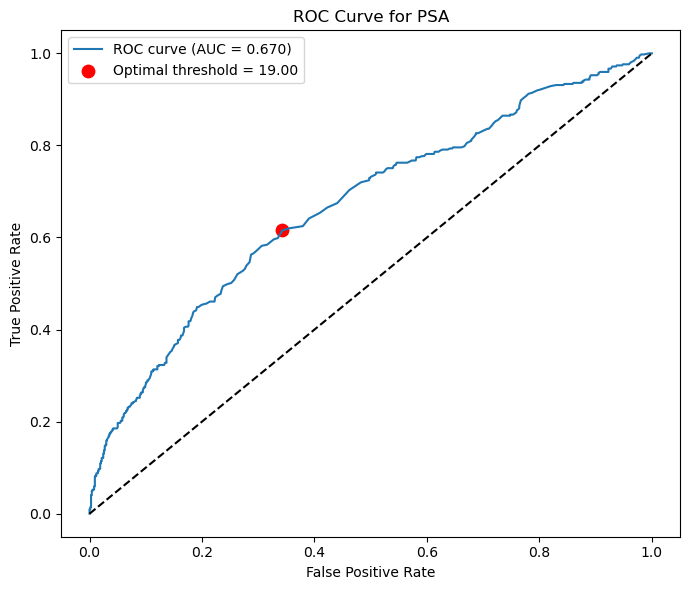

In [39]:
# Extract PSA and metastasis outcome
y = DATASET123["metastasis"].values
psa = DATASET123["psa"].values

# Compute ROC curve
fpr, tpr, thresholds = roc_curve(y, psa)
auc = roc_auc_score(y, psa)

# Compute distance to the upper-left corner (0,1)
distances = np.sqrt((fpr - 0)**2 + (tpr - 1)**2)

# Find threshold with minimum distance
min_dist_idx = np.argmin(distances)
optimal_threshold = thresholds[min_dist_idx]
optimal_sensitivity = tpr[min_dist_idx]
optimal_specificity = 1 - fpr[min_dist_idx]

print("AUC:", auc)
print("Optimal PSA threshold:", optimal_threshold)
print("Sensitivity at optimal threshold:", optimal_sensitivity)
print("Specificity at optimal threshold:", optimal_specificity)

# Plot ROC curve with optimal point highlighted
plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})")
plt.scatter(fpr[min_dist_idx], tpr[min_dist_idx], color='red', s=80,
            label=f"Optimal threshold = {optimal_threshold:.2f}")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for PSA")
plt.legend()
plt.tight_layout()
plt.show()


### Task 4 - Principal Component Analysis
We reduce the biomarker panel (monocyte through coag_factor) to a smaller set of uncorrelated components, standardizing first since PCA is scale-sensitive.


In [40]:
biomarkers = DATASET123.loc[:, "monocyte":"coag_factor"].columns.tolist()
print(biomarkers)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(DATASET123[biomarkers])

pca = PCA()
components = pca.fit_transform(scaled_data)


['monocyte', 'urea', 'lymphocyte', 'thrombocyte', 'erythrocyte', 'albumin', 'creatinine', 'globulin', 'psa', 'coag_factor']


#### Scree plot and eigenvalue > 1 criterion


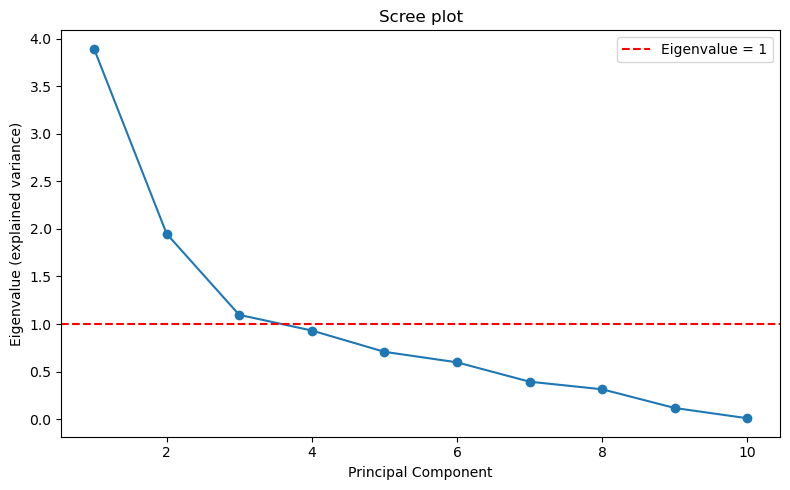

Components with eigenvalue > 1: 3
Cumulative variance explained: 0.693


In [41]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(pca.explained_variance_) + 1), pca.explained_variance_,
         marker="o")
plt.axhline(1, color="red", linestyle="--", label="Eigenvalue = 1")
plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue (explained variance)")
plt.title("Scree plot")
plt.legend()
plt.tight_layout()
plt.show()

n_components = int((pca.explained_variance_ > 1).sum())
print(f"Components with eigenvalue > 1: {n_components}")
print(f"Cumulative variance explained: {pca.explained_variance_ratio_[:n_components].sum():.3f}")


By the eigenvalue > 1 criterion, 3 components are retained (eigenvalues 3.90, 1.95, 1.10 - the 4th drops to 0.93), jointly explaining ~69% of total variance in the biomarker panel.

#### Component loadings

In [42]:
loadings = pd.DataFrame(
    pca.components_[:n_components].T,
    index=biomarkers,
    columns=[f"PC{i+1}" for i in range(n_components)]
)
loadings

,PC1,PC2,PC3
monocyte,0.381359,0.111550,-0.136535
urea,-0.290477,-0.041063,-0.478874
lymphocyte,0.347675,0.167079,0.051019
thrombocyte,0.411559,0.244749,-0.225448
erythrocyte,0.412421,0.198980,-0.260462
albumin,-0.132153,0.592537,0.248307
creatinine,-0.323013,0.532429,-0.047331
globulin,-0.127964,0.435897,-0.344857
psa,-0.085428,0.172973,0.600156
coag_factor,-0.405418,-0.062882,-0.296239


Interpretation: inspect which biomarkers have the largest absolute loading on each PC (dominant sign and magnitude), and check the printed `loadings` table above for the actual values before writing this section in the report - the grouping (e.g. inflammatory markers vs. renal markers vs. PSA/coag_factor) depends on values not hardcoded here.


#### Export dataset with retained components

In [43]:
pcs = pd.DataFrame(
    components[:, :n_components],
    columns=[f"PC{i+1}" for i in range(n_components)]
)
DATASET123 = pd.concat([DATASET123, pcs], axis=1)
DATASET123.to_csv("DATASET.csv", index=False)
DATASET123.head()

,ID,civil_status,cancer_family,prostdtfirst,metastasis,date_met,birthdate,age_at_diagnosis,age_at_metastasis,monocyte,...,hearing_loss,hypercholesterolaemia,hypertension,osteoporosis,urinary_retention,test_result20,test_result100,PC1,PC2,PC3
0,1,1,1,2017-03-16,0,NaN,1935-01-01,82.203970,NaN,46.14,...,0,0,0,1,0,1,1,-1.205222,-0.355442,-0.515687
1,2,2,0,2005-03-31,0,NaN,1942-01-01,63.244353,NaN,50.14,...,0,0,0,0,0,0,0,-0.507886,-1.418185,1.097049
2,3,2,0,2017-08-08,0,NaN,1959-01-01,58.600958,NaN,49.86,...,0,0,0,1,0,0,0,0.808393,-0.195869,0.597930
3,4,2,0,2008-01-02,0,NaN,1934-02-01,73.916496,NaN,49.57,...,0,0,0,0,0,0,0,-0.301166,-0.571948,0.478331
4,5,2,0,2006-05-08,0,NaN,1949-03-01,57.185489,NaN,57.00,...,0,0,0,0,0,0,0,2.483636,0.119847,-0.410740


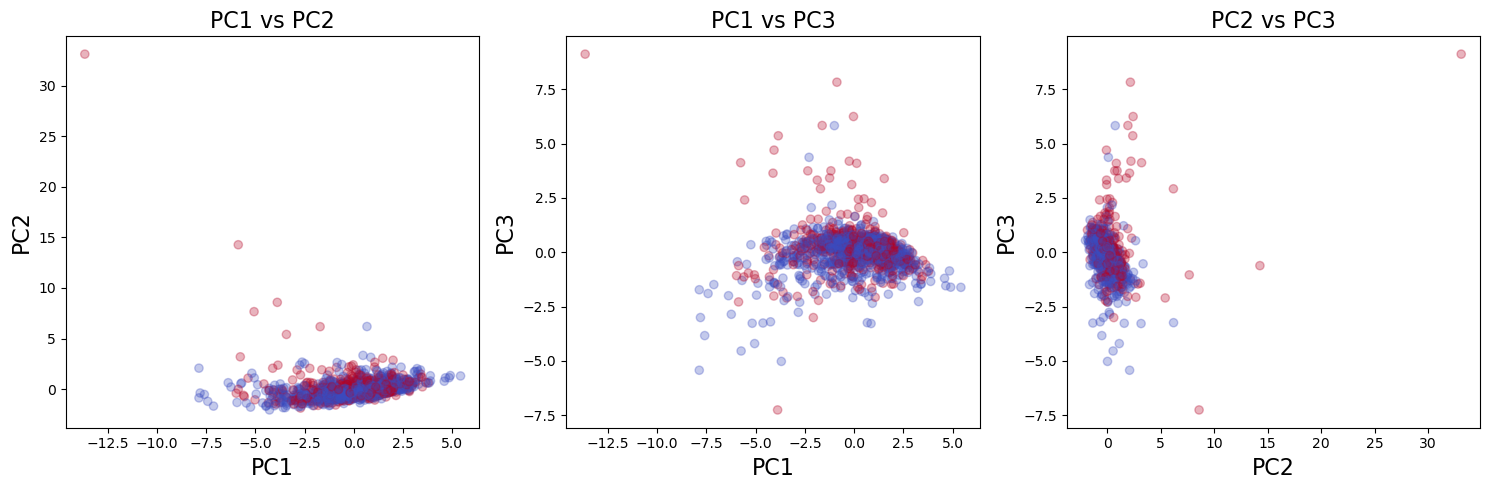

In [44]:
pc1 = DATASET123['PC1']
pc2 = DATASET123['PC2']
pc3 = DATASET123['PC3']
y = DATASET123['metastasis']  # outcome variable

plt.figure(figsize=(15, 5))

# PC1 vs PC2
plt.subplot(1, 3, 1)
plt.scatter(pc1, pc2, c=y, cmap='coolwarm', alpha=0.3)
plt.xlabel('PC1', fontsize=16)
plt.ylabel('PC2', fontsize=16)
plt.title('PC1 vs PC2', fontsize=16)

# PC1 vs PC3
plt.subplot(1, 3, 2)
plt.scatter(pc1, pc3, c=y, cmap='coolwarm', alpha=0.3)
plt.xlabel('PC1', fontsize=16)
plt.ylabel('PC3', fontsize=16)
plt.title('PC1 vs PC3', fontsize=16)

# PC2 vs PC3
plt.subplot(1, 3, 3)
plt.scatter(pc2, pc3, c=y, cmap='coolwarm', alpha=0.3)
plt.xlabel('PC2', fontsize=16)
plt.ylabel('PC3', fontsize=16)
plt.title('PC2 vs PC3',fontsize=16)

plt.tight_layout()
plt.show()
